In [1]:
import numpy as np
from matplotlib import pyplot as plt

from tof_helper_functions.tof_framework import RebinnedTOFPointList

In [2]:
def read_tof_tobias(filename):
    data = np.loadtxt(filename, delimiter="\t")
    v_tobi , v_N_tobi = [], []
    for i in range(len(data)):
        v_tobi = np.append(v_tobi, data[i][0])
        v_N_tobi = np.append(v_N_tobi, data[i][1])
    return v_tobi, v_N_tobi

Text(0.5, 1.0, 'Original and reprocessed TOF spectra from Tobias')

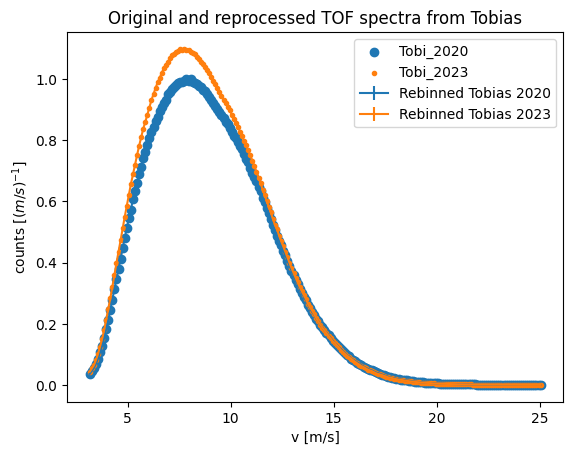

In [3]:
tobias_path = "C:/Users/fisch/Documents/TU/04 Viertes Semester/Grenoble/Projektarbeit/Auswertung/qBounce_turbine_sweetspot/messungen_tobias/"
v_tobi_2020, v_N_tobi_2020 = read_tof_tobias(tobias_path + "PF2EDM_vof_2020.txt")
v_tobi_2023, v_N_tobi_2023 = read_tof_tobias(tobias_path + "PF2EDM_vof_2023.txt")

v_min = 3.1
v_max = 25.1
v_step = 0.1



rebinned_tobi_2020 = RebinnedTOFPointList(  [v_tobi_2020,v_N_tobi_2020],
                                            v_min = v_min,
                                            v_max = v_max,
                                            v_step = v_step,
                                            label = "Rebinned Tobias 2020")
rebinned_tobi_2023 = RebinnedTOFPointList(  [v_tobi_2023,v_N_tobi_2023],
                                            v_min = v_min,
                                            v_max = v_max,
                                            v_step = v_step,
                                            label = "Rebinned Tobias 2023")
plt.scatter(v_tobi_2020, v_N_tobi_2020, label="Tobi_2020")
plt.errorbar(rebinned_tobi_2020.v, rebinned_tobi_2020.N_v, rebinned_tobi_2020.N_v_err, label=rebinned_tobi_2020.label)
plt.scatter(v_tobi_2023, v_N_tobi_2023, label="Tobi_2023", marker='.')
plt.errorbar(rebinned_tobi_2023.v, rebinned_tobi_2023.N_v, rebinned_tobi_2023.N_v_err, label=rebinned_tobi_2023.label)
plt.legend()
plt.xlabel("v [m/s]")
plt.ylabel(r"counts [$(m/s)^{-1}$]")
plt.title("Original and reprocessed TOF spectra from Tobias")



Mean velocity for Rebinned Tobias 2020 = 9.0297 +- 0.0000 m/s
Root mean squared velocity for Rebinned Tobias 2020 = 9.4853 +- 0.0000 m/s
Fit parameters: A=0.99+-0.00, mean=8.0041+-0.0118, sigma=3.15+-0.04
Encountered error when dividing by sigma
Mean velocity for Rebinned Tobias 2023 = 8.9100 +- 0.0000 m/s
Root mean squared velocity for Rebinned Tobias 2023 = 9.3601 +- 0.0000 m/s
Fit parameters: A=1.09+-0.00, mean=7.8528+-0.0134, sigma=3.15+-0.04
Encountered error when dividing by sigma


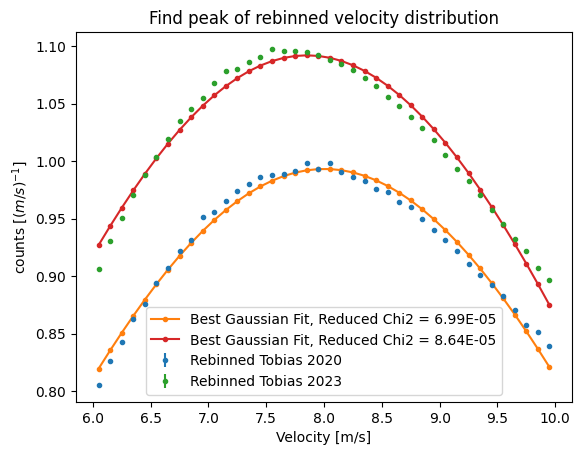

In [4]:
# get velocities
v_low, v_high = 6.0, 10.0

v_mean_2020, v_mean_2020_err = rebinned_tobi_2020.find_mean_velocity(do_print=True)
v_rms_2020, v_rms_2020_err = rebinned_tobi_2020.find_rms_velocity(do_print=True)
v_peak_2020, v_peak_2020_err = rebinned_tobi_2020.find_peak_velocity(gausstype='threepoints', 
                                                                         v_low=v_low, 
                                                                         v_high=v_high, 
                                                                         a0 = 1.0, 
                                                                         mu0= 8.0, 
                                                                         sigma0=1.0, 
                                                                         do_plot=True, 
                                                                         do_print=True)

v_mean_2023, v_mean_2023_err = rebinned_tobi_2023.find_mean_velocity(do_print=True)
v_rms_2023, v_rms_2023_err = rebinned_tobi_2023.find_rms_velocity(do_print=True)
v_peak_2023, v_peak_2023_err = rebinned_tobi_2023.find_peak_velocity(gausstype='threepoints', 
                                                                         v_low=v_low, 
                                                                         v_high=v_high, 
                                                                         a0 = 1.0, 
                                                                         mu0= 8.0, 
                                                                         sigma0=1.0, 
                                                                         do_plot=True, 
                                                                         do_print=True)


